In [6]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append('..')

import json
import numpy as np

import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable

import lpdo_utils
import noise_channels
from tqdm import tqdm
import quimb.tensor as qtn

mpl.rc('text', usetex=True)
mpl.rcParams['text.latex.preamble'] = r"\usepackage{amsmath} \usepackage{xfrac} \usepackage{amsfonts}"

tex_fonts = {"font.family": "serif",
             "font.size": 11,
             "axes.labelsize": 11,
             "legend.fontsize": 11,
             "xtick.labelsize": 8,
             "ytick.labelsize": 8}

plt.rcParams.update(tex_fonts)

marker_options = {'marker': 'o',
                  'markeredgecolor': 'black',
                  'markeredgewidth': 1.0,
                  'markersize': 5}

cmap = sns.color_palette('deep', as_cmap=True)

def set_size(width="revtex4.2", fraction=1, subplots=(1, 1), golden_ratio = 0.6180339887498949):
    """Set figure dimensions to avoid scaling in LaTeX.

    Parameters
    ----------
    width: float or string
            Document width in points, or string of predined document type
    fraction: float, optional
            Fraction of the width which you wish the figure to occupy
    subplots: array-like, optional
            The number of rows and columns of subplots.
    Returns
    -------
    fig_dim: tuple
            Dimensions of figure in inches
    """
    if width == 'revtex4.2':
        width_pt = 510.0
    else:
        width_pt = width

    # Width of figure (in pts)
    fig_width_pt = width_pt * fraction
    # Convert from pt to inches
    inches_per_pt = 1 / 72.27

    # Figure width in inches
    fig_width_in = fig_width_pt * inches_per_pt
    # Figure height in inches
    fig_height_in = fig_width_in * golden_ratio * (subplots[0] / subplots[1])

    return (fig_width_in, fig_height_in)

def load_training_results(file_name: str, data_folder = "../data/optimisation_data/"):
    """
    Save results of the function 'optimize_tn' in json format. 
    Complex values are transformed into strings for json serialisation.
    """
    with open(data_folder + file_name, 'r') as file:
        res = json.load(file)

        # Params during training
        res['params'] = [{int(k): np.array(v, dtype=complex) for k, v in p.items()} for p in res['params']]

        # Params of the MPOs, self-explanatory
        mpo_params_keys = [] #['params_true_mpo', 'params_inv_opt_mpo', 'params_inv_true_mpo']
        for key in mpo_params_keys:
            res[key] = {int(k): np.real_if_close(np.array(v, dtype=complex)) for k, v in res[key].items()}
        
        ignore_keys = ['probs', 'data_file', 'params', 'noise_type', 'lr', 'params_true_mpo', 'params_inv_opt_mpo', 'params_inv_true_mpo'] + mpo_params_keys
        for k in set(res.keys()).difference(ignore_keys):
            res[k] = np.real_if_close(np.array(res[k], dtype=complex))
        
    return res

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [7]:
coherent_depol = {'1e7': ['cxeven_nq10_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns10000000_global_repeated_sic_states_2023-11-16_seed13.json',
                          'cxeven_nq10_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns10000000_global_repeated_sic_states_2023-11-16_seed13.json',
                          'cxeven_nq10_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns10000000_global_repeated_sic_states_2023-11-16_seed101.json']}

depol = {'1e7': ['cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns10000000_global_repeated_sic_states_2023-11-13_seed99.json',
                 'cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns10000000_global_repeated_sic_states_2023-11-13_seed718.json',
                 'cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns10000000_global_repeated_sic_states_2023-11-13_seed999.json']}

spl_kyiv = {'1e7': ['cxeven_nq10_gen_dict_bigger_231127_kyiv_50q_ns10000000_global_repeated_sic_states_2023-11-30_seed100.json',
                    'cxeven_nq10_gen_dict_bigger_231127_kyiv_50q_ns10000000_global_repeated_sic_states_2023-11-30_seed103.json',
                    'cxeven_nq10_gen_dict_bigger_231127_kyiv_50q_ns10000000_global_repeated_sic_states_2023-11-30_seed108.json']}

shots_keys = ['1e7']
metrics_keys = ['frob_distance', 'test_loss', 'lpdo_trace', 'params']

noise_models = {'depol': depol, 'coherent_depol': coherent_depol, 'spl_kyiv': spl_kyiv}

processed_data = {}
for noise_type, noise_data in noise_models.items():  
    print(f"\nProcessing {noise_type}:")         
    
    for shots, files in noise_data.items():
        
        tmp_dict = {k: [] for k in metrics_keys}
        for f in files:
            print(f" > Loading and processing file: {f}")
            data = load_training_results(f)
            [tmp_dict[k].append(data[k]) for k in tmp_dict.keys()]

        idx_min_loss = [np.argmin(yy) for yy in tmp_dict['test_loss']]
        best_losses = np.array([p[idx] for p, idx in zip(tmp_dict['test_loss'], idx_min_loss)])
        best_frob_dists = np.array([p[idx] for p, idx in zip(tmp_dict['frob_distance'], idx_min_loss)])
        print(best_frob_dists, best_losses)
        min_loss_idx = np.argmin(best_losses)
        print(best_losses, np.argmin(best_losses), idx_min_loss, idx_min_loss[min_loss_idx])
        best_params = tmp_dict['params'][min_loss_idx][idx_min_loss[min_loss_idx]]

    processed_data[noise_type] = best_params


Processing depol:
 > Loading and processing file: cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns10000000_global_repeated_sic_states_2023-11-13_seed99.json
 > Loading and processing file: cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns10000000_global_repeated_sic_states_2023-11-13_seed718.json
 > Loading and processing file: cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns10000000_global_repeated_sic_states_2023-11-13_seed999.json
[1.05059456e-05 1.34244600e-05 1.27698934e-05] [5.48082234 5.47130832 5.46394611]
[5.48082234 5.47130832 5.46394611] 2 [3, 3, 3] 3

Processing coherent_depol:
 > Loading and processing file: cxeven_nq10_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns10000000_global_repeated_sic_states_2023-11-16_seed13.json
 > Loading and processing file: cxeven_nq10_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns10000000_global_repeated_sic_states_2023-11-16_seed13.json
 > Loading and processing file: cxeven_nq10_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns10000000_global_repeated_sic_states_

In [8]:
mpos_dict = {}
for n in noise_models:
    num_qubits = len(processed_data[n])
    opt_params = processed_data[n]

    # Create LPDO and MPO (in PTM form) with such optimal parametes
    opt_lpdo = lpdo_utils.build_lpdo(tn_data = opt_params.values())   
    #opt_lpdo, _ = training_functions.optimize_trace_preservation(opt_lpdo, steps=1000, plot_results=False)
    opt_mpo = lpdo_utils.lpdo_to_mpo(opt_lpdo)

    # Create true LPDO and MPO (in PTM form) for the corresponding noise
    noise_type = {'depol': 'even_depol1e-3_odd_depol5e-4', 'coherent_depol': 'coherent1e-3_even_depol1e-3_odd_depol5e-4', 'spl_kyiv': 'gen_dict_bigger_231127_kyiv_50q'}[n]
    true_lpdo = noise_channels.select_noise_channel(noise_type, num_qubits, tensor_type = 'lpdo')
    true_mpo  = noise_channels.select_noise_channel(noise_type, num_qubits, tensor_type = 'mpo')

    print(f"Noise {n}:")    
    print(f"Tr[LPDO] = {lpdo_utils.trace_lpdo(opt_lpdo)}")
    print(f"‖ LPDO_opt - LPDO_true ‖_Frob = {(opt_lpdo.distance(true_lpdo) / 2**num_qubits) ** 2}") 
    print(f"‖ MPO_opt  - MPO_true ‖_Frob = {(opt_mpo.distance(true_mpo) / 2**num_qubits) ** 2}\n") 

    mpos_dict[n] = [opt_mpo, true_mpo]

Noise depol:
Tr[LPDO] = (1024.0135498046875-5.5534023601921945e-08j)
‖ LPDO_opt - LPDO_true ‖_Frob = 1.2769893366182393e-05
‖ MPO_opt  - MPO_true ‖_Frob = 1.2769893364739103e-05

Noise coherent_depol:
Tr[LPDO] = (1024.0228271484375-2.0474203665798996e-07j)
‖ LPDO_opt - LPDO_true ‖_Frob = 1.5416570192217094e-05
‖ MPO_opt  - MPO_true ‖_Frob = 1.541657019044074e-05

Noise spl_kyiv:
Tr[LPDO] = (1024.018798828125-4.89293995542539e-07j)
‖ LPDO_opt - LPDO_true ‖_Frob = 0.0001098717612499911
‖ MPO_opt  - MPO_true ‖_Frob = 0.00010987176124743757



In [9]:
def pauli_index_to_string(pauli_index):
    index_to_key = {0: 'I', 1: 'X', 2: 'Y', 3: 'Z'}
    return [index_to_key[p] for p in pauli_index]

def pauli_string_to_index(pauli_string):
    # Remove unnecessary sign
    if (pauli_string[0] == '+') or (pauli_string[0] == '-'):
        pauli_string = pauli_string[1:]
    index_to_key = {'I': 0, '_': 0, 'X': 1, 'Y': 2, 'Z': 3}
    return [index_to_key[p] for p in pauli_string]

def pauli_index_to_multindex(pauli_index, state_space = 4):
    one_hot_matrix = np.zeros((len(pauli_index), state_space))
    one_hot_matrix[range(len(pauli_index)), pauli_index] = 1
    return one_hot_matrix

pauli_strings = np.array([['I',]*num_qubits,]*50)

size = len(pauli_strings) // num_qubits
groups = [range(i*size, (i+1) * size) for i in range(len(pauli_strings) // size)]
pauli_weights = np.linspace(1, num_qubits, len(groups), dtype=int)

for pauli_weight, gidx in zip(pauli_weights, groups):
    for j in gidx:
        idx = np.random.choice(range(num_qubits), pauli_weight, replace=False)
        pauli_strings[j][idx] = np.random.choice(['X', 'Y', 'Z'], pauli_weight)   

pauli_strings = ['I'*num_qubits] + pauli_strings.tolist()
pauli_strings = [''.join(s) for s in pauli_strings]

In [ ]:
mpo_vals_dict = {}
for n, (opt_mpo, true_mpo) in mpos_dict.items():

    res_coeffs = {}
    for p in tqdm(pauli_strings):

        pauli_index = pauli_string_to_index(p)
        pauli_index = pauli_index_to_multindex(pauli_index)
        
        in_mps  = qtn.MPS_product_state(pauli_index, site_ind_id = 'k{}')
        out_mps = qtn.MPS_product_state(pauli_index, site_ind_id = 'b{}')
        
        res_coeffs [p] = {'opt_mpo' : (in_mps | opt_mpo | out_mps).contract(),
                          'true_mpo': (in_mps | true_mpo | out_mps).contract()}
        
    opt_mpo_val  = np.array([res_coeffs[p]['opt_mpo'] for p in pauli_strings])
    true_mpo_val = np.array([res_coeffs[p]['true_mpo'] for p in pauli_strings])
    mpo_vals_dict[n] = ((opt_mpo, true_mpo), (opt_mpo_val, true_mpo_val))

100%|██████████| 51/51 [00:00<00:00, 363.45it/s]


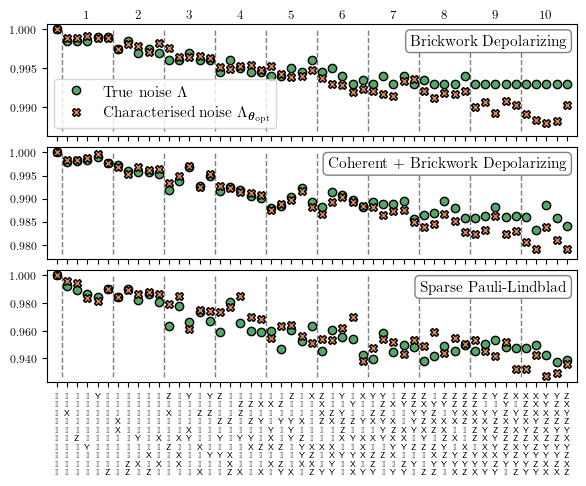

In [12]:
fig, axs = plt.subplots(3, 1, figsize = (6, 5), sharex=True)

xticks_labels = [''.join([r'$\textsf{' + ps + r'}$' + ' \n ' for ps in p])[:-3] for p in pauli_strings]
xticks_labels2 = [p.replace('\\textsf{I}', '\\mathbb{I}') for p in xticks_labels]

for ax, (noise_id, ((opt_mpo, true_mpo), (opt_mpo_val, true_mpo_val))) in zip(axs, mpo_vals_dict.items()):

    xx = range(len(opt_mpo_val))
    ax.plot(xx, true_mpo_val, lw = 0,  marker = 'o', markeredgecolor = 'k', color = cmap[2])
    ax.plot(xx, opt_mpo_val, lw = 0, marker = 'X', markeredgecolor = 'k', color = cmap[1])

    min_y = min(min(opt_mpo_val), min(true_mpo_val))
    max_y = max(max(opt_mpo_val), max(true_mpo_val))
    ax.vlines(0.5, min_y - 0.001, 1, ls = "--", color="k", lw=1, alpha = 0.5)
    ax.vlines([max(g) + 1.5 for g in groups[:-1]], min_y - 0.001, 1, ls = "--", color="k", lw = 1, alpha = 0.5)

    #ax.set_ylim([min_y- 0.002, 1.001])
    ax.set_xlim([-1, 51])

from matplotlib.ticker import FormatStrFormatter
axs[2].yaxis.set_major_formatter(plt.FormatStrFormatter('%.3f'))
#axs[0].set_yticks([0.99, 1])
#axs[1].set_yticks([0.98, 0.99, 1])
#axs[2].set_yticks([0.94, 0.96, 0.98, 1])

[axs[0].text(1 + int(min(g) + (max(g) - min(g)) / 2),  1 + 0.0015, f"{w+1}", ha="center", fontsize = 9) for w, g in enumerate(groups)]

axs[2].set_xticks(xx, labels = xticks_labels2, fontsize=6)

axs[0].annotate("Brickwork Depolarizing", xy=(len(xticks_labels) - 1, 0.99935), ha="right", va="top", bbox=dict(boxstyle="round,pad=0.3", fc="w", ec="grey", lw=1))
axs[1].annotate("Coherent + Brickwork Depolarizing", xy=(len(xticks_labels) - 1, 0.999), ha="right", va="top", bbox=dict(boxstyle="round,pad=0.3", fc="w", ec="grey", lw=1))
axs[2].annotate("Sparse Pauli-Lindblad", xy=(len(xticks_labels) - 1, 0.9965), ha="right", va="top", bbox=dict(boxstyle="round,pad=0.3", fc="w", ec="grey", lw=1))

axs[0].plot([], [], lw = 0, marker = 'o', markeredgecolor = 'k', color = cmap[2], label = r"True noise $\Lambda$")
axs[0].plot([], [], lw = 0, marker = 'X', markeredgecolor = 'k', color = cmap[1], label = r"Characterised noise $\Lambda_{\boldsymbol{\theta_{\text{opt}}}}$")
axs[0].legend(loc=3)

plt.tight_layout()
fig.subplots_adjust(hspace = 0.1)
plt.savefig('accuracy_coeffs.pdf', format="pdf")